# Introduction to Machine Learning – Lab 2
## Comparison of Data Preparation Strategies

### Objective
Notebook 02 evaluated the XGBoost classifier with one data preparation setup. This notebook repeats all of its experiments for different data preparation strategies and compares the results. Starting from the setup of notebook 02 (the **baseline**), every variant changes exactly one thing; the variants are listed in Section 1. Two of them are methods for imbalanced classes from the lecture: **SMOTE** and **class weights**.

### Experiments Conducted
For every variant, the same experiments as in notebook 02, with the default XGBoost model:
1. **Holdout split:** 10% and 20% test set, each with and without stratification, for 10 split seeds each (40 splits).
2. **k-fold cross-validation:** $k=5$ and $k=10$, each with `KFold` and `StratifiedKFold` (30 folds).
3. **Methods for imbalanced classes:** their effect on each price class, from the out-of-fold predictions of the stratified 5-fold cross-validation.

**Paired comparison:** all splits are drawn once, on the 2,925 houses of the baseline, and every variant is fitted and scored on exactly the same splits. Differences between variants therefore never come from different test houses. In the variant that keeps the extreme houses, these 5 houses are added to the training part of every split, but never used as test houses.

**Metrics:** accuracy and macro-F1 (main metric, as in notebook 02).

Running all experiments takes about 13 minutes (11 variants × 70 fitted models).

### 1. Data and variants

In [1]:
import sys
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.utils.class_weight import compute_sample_weight
from evaluation import evaluate, make_splits, paired_differences, summarize
from preprocessing import (
    CLASS_NAMES, EXTREME_AREA, NEAR_CONSTANT, REDUNDANT, build_pipeline, load_raw, make_preprocessor,
    prepare_data, smote_keep_missing,
)

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

# All 2,930 houses; the experiments only test on the houses up to 4,000 ft² living area
X, y = prepare_data(DATA_PATH)
raw = load_raw(DATA_PATH)
normal_houses = X.index[X["Gr Liv Area"] <= EXTREME_AREA]
extreme_houses = X.index[X["Gr Liv Area"] > EXTREME_AREA]

print(f"{len(normal_houses):,} houses up to {EXTREME_AREA:,} ft², {len(extreme_houses)} extreme houses:")
display(raw.loc[extreme_houses, ["Gr Liv Area", "SalePrice", "Sale Condition"]])

2,925 houses up to 4,000 ft², 5 extreme houses:


,Gr Liv Area,SalePrice,Sale Condition
1498,5642,160000,Partial
1760,4476,745000,Abnorml
1767,4316,755000,Normal
2180,5095,183850,Partial
2181,4676,184750,Partial


In [2]:
# Share of the most frequent value of each nearly constant feature (raw values)
near_constant = pd.DataFrame(
    {
        "Most Frequent Value": [raw[col].mode()[0] for col in NEAR_CONSTANT],
        "Share (%)": [raw[col].value_counts(normalize=True).iloc[0] * 100 for col in NEAR_CONSTANT],
    },
    index=NEAR_CONSTANT,
).round(2)
display(near_constant)


def similarity(dropped, kept):
    """How closely a redundant feature follows the feature that is kept instead."""
    if isinstance(X[dropped].dtype, pd.CategoricalDtype):
        same = (X[dropped].astype(str) == X[kept].astype(str)).mean()
        return f"same value for {same:.0%} of the houses"
    return f"Spearman r = {X[dropped].corr(X[kept], method='spearman'):.2f}"


redundant = pd.DataFrame(
    [{"Dropped": dropped, "Kept": kept, "Similarity": similarity(dropped, kept)} for dropped, kept in REDUNDANT.items()]
)
display(redundant)

,Most Frequent Value,Share (%)
Utilities,AllPub,99.90
Street,Pave,99.59
Condition 2,Norm,98.98
Roof Matl,CompShg,98.53
Heating,GasA,98.46
Pool QC,NA,99.56
Misc Feature,NA,96.38


,Dropped,Kept,Similarity
0,Garage Yr Blt,Year Built,Spearman r = 0.90
1,Garage Cars,Garage Area,Spearman r = 0.86
2,TotRms AbvGrd,Gr Liv Area,Spearman r = 0.81
3,1st Flr SF,Total Bsmt SF,Spearman r = 0.83
4,Exterior 2nd,Exterior 1st,same value for 85% of the houses


* **Extreme houses:** three of the five houses above 4,000 ft² are partial sales (houses not yet finished when sold) for only \$160,000–\$184,750, far below what their size suggests. The other two sold for \$745,000 and \$755,000. The documentation of the dataset recommends removing these five houses.
* **Nearly constant features:** for all seven, 96.4–99.9% of the houses share the same value, so each of them can only separate a handful of houses.
* **Redundant features:** each dropped feature measures almost the same thing as the feature kept instead (Spearman $r$ = 0.81–0.90; Exterior 2nd equals Exterior 1st for 85% of the houses). 1st Flr SF even follows exactly from Gr Liv Area − 2nd Flr SF − Low Qual Fin SF.

* **Imbalanced price classes:** the two middle classes hold 58.8% of the houses, while `≥ 400k` has only 2.1% (62 houses) and `< 100k` 8.1% (notebook 02). In notebook 03, the outer classes lost about a third of their houses to their larger neighbors (recall 0.677 for `≥ 400k`, 0.641 for `< 100k`). Two methods from the lecture are added as variants:
  * **SMOTE** (Synthetic Minority Over-sampling Technique) creates new houses for the smaller classes. For a house $x_i$ of a small class, one of its $k = 5$ nearest neighbors $x_{nn}$ in the same class is chosen at random, and a synthetic house is placed on the line between the two: $x_{new} = x_i + \lambda\,(x_{nn} - x_i)$ with $\lambda \sim U(0, 1)$. This is repeated until every class is as large as the largest one. Only the training part of each split is resampled; the test houses are always real houses.
    * SMOTE needs complete numeric data, so the neighbor search and the interpolation run on median-filled, standardized features (`smote_keep_missing` in `preprocessing.py`). The real houses reach XGBoost unchanged, with their missing values.
    * One-hot and other integer features of the synthetic houses are rounded, so that, e.g., a neighborhood column stays 0 or 1.
  * **Class weights** add no houses. Instead, every training house gets the weight $w_c = \frac{n}{6 \cdot n_c}$ of its class $c$ ($n$ training houses, $n_c$ of them in class $c$) in the loss, so every class has the same total weight. A house ≥ \$400k then counts about 17 times as much as a house of \$130k–\$180k.
  * **Threshold moving**, the third common method, does not change the training; it was evaluated in notebook 03, Section 5.

In [3]:
def balanced_weights(y_train):
    """Weight n / (6 · n_c) for every house, so that every price class has the same total weight."""
    return compute_sample_weight("balanced", y_train)


def variant(name, change, strategy="onehot", keep_extreme=False, smote=False, class_weights=False, **data_options):
    """One data preparation variant: the baseline with one change."""
    return {
        "Variant": name,
        "Change": change,
        "strategy": strategy,
        "keep_extreme": keep_extreme,
        "smote": smote,
        "weight_fn": balanced_weights if class_weights else None,
        "data_options": {"drop_near_constant": True, **data_options},
    }


VARIANTS = [
    variant("Baseline", "Setup of notebook 02: one-hot encoding, no nearly constant features, no extreme houses"),
    variant("Keep nearly constant", "The 7 nearly constant features stay in the data", drop_near_constant=False),
    variant("Keep extreme houses", "The 5 extreme houses are added to the training part of every split", keep_extreme=True),
    variant("Ordinal encoding", "Nominal features as one integer per category", strategy="ordinal"),
    variant("Target encoding", "Nominal features as the smoothed share of each price class per category", strategy="target"),
    variant("Native categories", "Nominal features handled by XGBoost itself", strategy="native"),
    variant("Size totals", "Adds Total SF, Total Bathrooms and Total Porch SF", add_size_totals=True),
    variant("Ages", "Adds Age At Sale and Years Since Remod", add_age_features=True),
    variant("Without redundant", "Drops the 5 redundant features listed above", drop_redundant=True),
    variant("SMOTE", "Synthetic houses for the smaller price classes until all 6 classes are equally large", smote=True),
    variant("Class weights", "Every training house weighted by n / (6 · n_c), the same total weight per class", class_weights=True),
]
BASELINE = VARIANTS[0]["Variant"]

# Features and price classes of each variant, for all 2,930 houses (the splits pick the houses)
data = {v["Variant"]: prepare_data(DATA_PATH, **v["data_options"]) for v in VARIANTS}

display(
    pd.DataFrame(
        [{"Variant": v["Variant"], "Change": v["Change"], "Features": data[v["Variant"]][0].shape[1]} for v in VARIANTS]
    ).set_index("Variant")
)

,Change,Features
Variant,,
Baseline,"Setup of notebook 02: one-hot encoding, no nea...",72
Keep nearly constant,The 7 nearly constant features stay in the data,79
Keep extreme houses,The 5 extreme houses are added to the training...,72
Ordinal encoding,Nominal features as one integer per category,72
Target encoding,Nominal features as the smoothed share of each...,72
Native categories,Nominal features handled by XGBoost itself,72
Size totals,"Adds Total SF, Total Bathrooms and Total Porch SF",75
Ages,Adds Age At Sale and Years Since Remod,74
Without redundant,Drops the 5 redundant features listed above,67


### 2. Running the experiments
The splits are drawn once on the 2,925 houses of the baseline: 40 holdout splits (4 setups × 10 seeds) and 30 cross-validation folds (5 + 5 + 10 + 10). Every variant is fitted and scored on all 70 of them.

In [4]:
splits = make_splits(y.loc[normal_houses])

results = []
for v in VARIANTS:
    X_v, y_v = data[v["Variant"]]
    extra_train = extreme_houses if v["keep_extreme"] else None
    pipeline = build_pipeline(v["strategy"], smote=v["smote"])
    scores = evaluate(pipeline, X_v, y_v, splits, extra_train=extra_train, weight_fn=v["weight_fn"])
    results.append(scores.assign(Variant=v["Variant"]))
    print(f"{v['Variant']}: done")

results = pd.concat(results, ignore_index=True)
print(f"{len(splits)} splits × {len(VARIANTS)} variants = {len(results)} fitted models")

Baseline: done


Keep nearly constant: done


Keep extreme houses: done


Ordinal encoding: done


Target encoding: done


...

Size totals: done


Ages: done


Without redundant: done


SMOTE: done


Class weights: done
70 splits × 11 variants = 770 fitted models


### 3. Results per variant
Mean ± standard deviation over the 10 seeds (holdout) or the $k$ folds (cross-validation). The standard deviation is the sample standard deviation, so the cross-validation values are slightly larger than in notebook 02, which used the population standard deviation; the means of the baseline are identical to notebook 02.

In [5]:
print("Test macro-F1")
display(summarize(results, "Test Macro-F1"))

print("Test accuracy")
display(summarize(results, "Test Accuracy"))

Test macro-F1


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
Baseline,0.7486 ± 0.0238,0.7596 ± 0.0342,0.7357 ± 0.0172,0.7546 ± 0.0245,0.7421 ± 0.0286,0.7494 ± 0.0236,0.7574 ± 0.0252,0.7546 ± 0.0432
Keep nearly constant,0.7497 ± 0.0296,0.7565 ± 0.0323,0.7361 ± 0.0197,0.7495 ± 0.0247,0.7408 ± 0.0244,0.7471 ± 0.0325,0.7438 ± 0.0183,0.7482 ± 0.0454
Keep extreme houses,0.7435 ± 0.0188,0.7606 ± 0.0369,0.7365 ± 0.0173,0.7474 ± 0.0219,0.7397 ± 0.0186,0.7440 ± 0.0290,0.7504 ± 0.0327,0.7478 ± 0.0353
Ordinal encoding,0.7476 ± 0.0263,0.7548 ± 0.0356,0.7297 ± 0.0247,0.7456 ± 0.0231,0.7359 ± 0.0238,0.7397 ± 0.0303,0.7381 ± 0.0220,0.7464 ± 0.0391
Target encoding,0.7459 ± 0.0269,0.7422 ± 0.0514,0.7322 ± 0.0302,0.7502 ± 0.0233,0.7306 ± 0.0326,0.7425 ± 0.0291,0.7429 ± 0.0265,0.7399 ± 0.0374
Native categories,0.7430 ± 0.0346,0.7491 ± 0.0411,0.7356 ± 0.0181,0.7558 ± 0.0253,0.7429 ± 0.0272,0.7392 ± 0.0306,0.7431 ± 0.0252,0.7315 ± 0.0408
Size totals,0.7587 ± 0.0362,0.7599 ± 0.0298,0.7484 ± 0.0255,0.7503 ± 0.0239,0.7486 ± 0.0112,0.7491 ± 0.0178,0.7365 ± 0.0171,0.7442 ± 0.0315
Ages,0.7458 ± 0.0265,0.7536 ± 0.0391,0.7342 ± 0.0198,0.7515 ± 0.0258,0.7368 ± 0.0221,0.7456 ± 0.0264,0.7532 ± 0.0208,0.7533 ± 0.0414
Without redundant,0.7521 ± 0.0276,0.7486 ± 0.0366,0.7398 ± 0.0189,0.7546 ± 0.0270,0.7434 ± 0.0296,0.7424 ± 0.0259,0.7453 ± 0.0238,0.7421 ± 0.0396


Test accuracy


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
Baseline,0.7546 ± 0.0198,0.7689 ± 0.0311,0.7547 ± 0.0121,0.7615 ± 0.0176,0.7542 ± 0.0235,0.7641 ± 0.0215,0.7648 ± 0.0212,0.7665 ± 0.0329
Keep nearly constant,0.7567 ± 0.0217,0.7621 ± 0.0207,0.7538 ± 0.0113,0.7569 ± 0.0164,0.7494 ± 0.0222,0.7672 ± 0.0270,0.7573 ± 0.0179,0.7658 ± 0.0334
Keep extreme houses,0.7488 ± 0.0205,0.7655 ± 0.0299,0.7515 ± 0.0119,0.7617 ± 0.0150,0.7494 ± 0.0218,0.7651 ± 0.0262,0.7600 ± 0.0235,0.7589 ± 0.0320
Ordinal encoding,0.7625 ± 0.0201,0.7601 ± 0.0226,0.7489 ± 0.0161,0.7590 ± 0.0147,0.7484 ± 0.0179,0.7634 ± 0.0257,0.7494 ± 0.0210,0.7596 ± 0.0274
Target encoding,0.7601 ± 0.0278,0.7590 ± 0.0260,0.7487 ± 0.0197,0.7595 ± 0.0189,0.7446 ± 0.0219,0.7600 ± 0.0244,0.7532 ± 0.0226,0.7552 ± 0.0406
Native categories,0.7587 ± 0.0308,0.7635 ± 0.0294,0.7526 ± 0.0177,0.7643 ± 0.0189,0.7545 ± 0.0219,0.7573 ± 0.0368,0.7535 ± 0.0254,0.7535 ± 0.0323
Size totals,0.7584 ± 0.0212,0.7648 ± 0.0237,0.7550 ± 0.0179,0.7603 ± 0.0179,0.7549 ± 0.0186,0.7600 ± 0.0204,0.7562 ± 0.0217,0.7627 ± 0.0320
Ages,0.7553 ± 0.0223,0.7659 ± 0.0253,0.7491 ± 0.0138,0.7622 ± 0.0188,0.7528 ± 0.0149,0.7648 ± 0.0221,0.7597 ± 0.0241,0.7644 ± 0.0334
Without redundant,0.7608 ± 0.0214,0.7628 ± 0.0259,0.7530 ± 0.0131,0.7662 ± 0.0170,0.7556 ± 0.0292,0.7641 ± 0.0167,0.7607 ± 0.0219,0.7607 ± 0.0285


In [6]:
# Training vs. test scores per variant, averaged over all 70 splits
gap = results.groupby("Variant", sort=False)[["Train Macro-F1", "Test Macro-F1"]].mean()
gap["Gap"] = gap["Train Macro-F1"] - gap["Test Macro-F1"]
display(gap.round(4))

,Train Macro-F1,Test Macro-F1,Gap
Variant,,,
Baseline,1.0000,0.7509,0.2491
Keep nearly constant,1.0000,0.7468,0.2532
Keep extreme houses,1.0000,0.7469,0.2531
Ordinal encoding,1.0000,0.7429,0.2571
Target encoding,0.9911,0.7414,0.2497
Native categories,1.0000,0.7427,0.2573
Size totals,1.0000,0.7495,0.2505
Ages,1.0000,0.7476,0.2524
Without redundant,1.0000,0.7465,0.2535


#### Interpretation of the results per variant
* **The data preparation variants are close.** The mean test macro-F1 of the baseline and of the eight data preparation variants lies between 0.730 and 0.761 in every setup. Within one setup they differ by at most 0.023, which is about as large as or smaller than the standard deviation over the splits (0.011–0.051).
* **SMOTE stands out on the holdout splits.** It has the best mean in all four holdout setups (0.7579–0.7800), 0.0125–0.0222 above the baseline, and also in 10-fold stratified cross-validation (0.7634 vs. 0.7546). In the other cross-validation setups it is close to the baseline (−0.0039 to +0.0024). Class weights are in between: 0.0069–0.0106 above the baseline in three holdout setups, below it in two cross-validation setups.
* **No variant wins in every setup.** SMOTE is best in five setups, class weights in one (CV $k=5$, 0.7518), and the baseline in the remaining two (CV $k=5$ stratified and CV $k=10$). Size totals, which looked promising on the unstratified holdout splits, is the worst variant with 10-fold cross-validation (0.737 vs. 0.757 for the baseline). Comparing means alone cannot settle this, which is why Section 4 compares the variants split by split.
* **Same overfitting for every variant.** All variants fit the training houses perfectly (training macro-F1 1.0, including SMOTE and class weights), and the gap to the test macro-F1 is 0.249–0.257 for all data preparation variants. The data preparation does not change the high variance found in notebook 02. The gap is smaller only for SMOTE (0.2376) and class weights (0.2455), and only because their test score is higher, not because the training fit is lower. Target encoding has a training macro-F1 of 0.991, a side effect of the encoder: during fitting it encodes the training houses with internal cross-fitting, during prediction with the encoder fitted on all training houses, so the model sees slightly different values for the same houses.

### 4. Paired differences to the baseline
For every split: the macro-F1 of a variant minus the macro-F1 of the baseline on the same split (positive = better than the baseline). Both are scored on the same test houses, so an easy or hard test set affects both scores in the same way. This shows how often a variant beats the baseline, which the mean ± standard deviation tables above cannot answer.

In [7]:
differences = paired_differences(results, BASELINE)
experiment = differences.index.get_level_values("Setup").str.split().str[0]  # "Holdout" or "CV"


def describe(diffs):
    """Mean and spread of the paired differences, and on how many splits the variant is better or worse."""
    return pd.DataFrame(
        {
            "Mean Difference": diffs.mean(),
            "Std": diffs.std(),
            "Better": (diffs > 0).sum(),
            "Worse": (diffs < 0).sum(),
        }
    )


groups = {name: describe(group) for name, group in differences.groupby(experiment, sort=False)}
groups["All 70 splits"] = describe(differences)
display(pd.concat(groups, axis=1).round(4))

Holdout                                   CV  \
                     Mean Difference     Std Better Worse Mean Difference   
Variant                                                                     
Keep nearly constant         -0.0017  0.0121     19    21         -0.0073   
Keep extreme houses          -0.0026  0.0142     16    24         -0.0059   
Ordinal encoding             -0.0052  0.0198     13    27         -0.0118   
Target encoding              -0.0070  0.0249     13    27         -0.0128   
Native categories            -0.0038  0.0161     16    24         -0.0140   
Size totals                   0.0047  0.0253     21    19         -0.0094   
Ages                         -0.0033  0.0178     18    22         -0.0033   
Without redundant            -0.0009  0.0173     21    19         -0.0091   
SMOTE                         0.0188  0.0262     30    10          0.0018   
Class weights                 0.0062  0.0211     26    14          0.0000   

                                            All 70 splits                       
                         Std Better Worse Mean Difference     Std Better Worse  
Variant                                                                         
Keep nearly constant  0.0150      9    21         -0.0041  0.0136     28    42  
Keep extreme houses   0.0170     13    17         -0.0040  0.0154     29    41  
Ordinal encoding      0.0193      7    23         -0.0080  0.0197     20    50  
Target encoding       0.0182      9    21         -0.0095  0.0223     22    48  
Native categories     0.0212     11    19         -0.0082  0.0190     27    43  
Size totals           0.0251     10    20         -0.0014  0.0260     31    39  
Ages                  0.0173     14    16         -0.0033  0.0174     32    38  
Without redundant     0.0153      7    23         -0.0044  0.0169     28    42  
SMOTE                 0.0235     14    16          0.0115  0.0263     44    26  
Class weights         0.0238     15    15          0.0036  0.0223     41    29

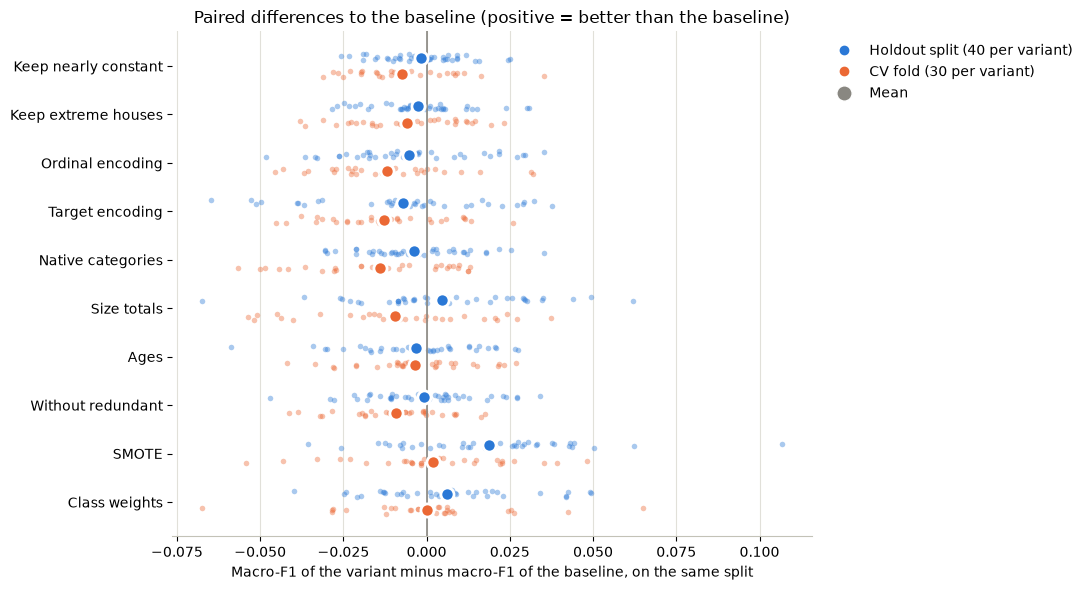

In [8]:
# One small dot per split, one large dot for the mean, per variant and experiment type
COLORS = {"Holdout": "#2a78d6", "CV": "#eb6834"}
LABELS = {"Holdout": "Holdout split", "CV": "CV fold"}
MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(11, 6))
for row, name in enumerate(differences.columns):
    for offset, (exp, color) in zip((-0.17, 0.17), COLORS.items()):
        values = differences.loc[experiment == exp, name]
        jitter = rng.uniform(-0.07, 0.07, len(values))
        ax.scatter(values, row + offset + jitter, s=16, color=color, alpha=0.4, linewidths=0)
        ax.scatter(values.mean(), row + offset, s=90, color=color, edgecolors="white", linewidths=2, zorder=3)

ax.axvline(0, color=MUTED, linewidth=1.2)
ax.set_yticks(range(len(differences.columns)), differences.columns)
ax.invert_yaxis()
ax.set_xlabel("Macro-F1 of the variant minus macro-F1 of the baseline, on the same split")
ax.set_title("Paired differences to the baseline (positive = better than the baseline)", fontsize=12)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)

handles = [
    Line2D([], [], marker="o", linestyle="", color=color, markersize=6, label=f"{LABELS[exp]} ({(experiment == exp).sum()} per variant)")
    for exp, color in COLORS.items()
]
handles.append(Line2D([], [], marker="o", linestyle="", color=MUTED, markeredgecolor="white", markersize=11, label="Mean"))
ax.legend(handles=handles, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.show()

#### Interpretation of the paired differences
* **No data preparation change improves on the baseline.** Over all 70 splits, the mean difference is negative for each of the eight data preparation variants (−0.0014 to −0.0095), and each is worse than the baseline on more splits than it is better. Only the two methods for imbalanced classes have a positive mean (see below). In the plot, the single splits scatter between about −0.07 and +0.11.
* **Other encodings (largest losses):** target encoding −0.0095 (worse on 48 of 70 splits), native categories −0.0082 (43 of 70), ordinal encoding −0.0080 (50 of 70). Possible explanations:
  * *Ordinal:* the integers follow the alphabetical order of the categories, which means nothing for the price. A tree needs several splits to isolate a single category (e.g. one neighborhood) and groups unrelated categories along the way.
  * *Native:* XGBoost searches for the best grouping of the categories at every split. With many categories (e.g. 28 neighborhoods) this is very flexible and fits the training houses even more closely.
  * *Target:* six columns per feature with the price-class shares of each category. For rare categories, these shares rest on a few houses and are noisy.
* **Nearly constant features and extreme houses (small losses):** keeping the nearly constant features costs −0.0041 (worse on 42 of 70), training on the extreme houses −0.0040 (41 of 70). Both fit the expectation: the nearly constant features can only separate a handful of houses, which mostly fits noise, and the three partial sales teach the trees that very large houses can be cheap.
* **Without redundant features (small loss):** −0.0044 (worse on 42 of 70). The dropped features are similar to the kept ones ($r$ = 0.81–0.90), but not identical, so a little information is lost.
* **New features (smallest differences):** Size totals −0.0014 (better on 31 of 70; better on the holdout splits with +0.0047, worse in cross-validation with −0.0094), Ages −0.0033 (better on 32 of 70). Ages adds almost nothing new: all houses were sold between 2006 and 2010, so Age At Sale is practically Year Built reversed ($r$ = −0.999), and the trees could already split on Year Built. Total SF follows Gr Liv Area closely (Spearman $r$ = 0.86), and the trees already combine the size features over several splits.
* **Methods for imbalanced classes (the only gains):** SMOTE +0.0115 (better on 44 of 70 splits), class weights +0.0036 (better on 41 of 70). Both gains come from the holdout splits: SMOTE +0.0188 (better on 30 of 40), class weights +0.0062 (26 of 40). On the cross-validation folds they are close to zero: SMOTE +0.0018 (better on 14, worse on 16), class weights 0.0000 (15 and 15). The training size does not explain the difference: holdout 10% and CV $k=10$ train on the same number of houses. But the 40 holdout splits come from 40 different random partitions of the data, while the 30 cross-validation folds come from only four partitions, all drawn with the same seed, so the cross-validation result may depend more on that one seed. Section 5 shows what both methods change per class.
* **How certain is this?** Apart from SMOTE (+0.0115), all mean differences are below 0.01 macro-F1, inside the spread of the single splits (standard deviation 0.012–0.026). The counts are consistent (e.g. ordinal worse on 50 of 70 splits), but the 70 splits overlap: the CV folds and the holdout seeds share most of their training houses, so they are not 70 independent tests. The safe reading: no data preparation variant is better than the baseline, and the encodings other than one-hot are probably slightly worse. SMOTE is probably slightly better, by about 0.01, but only the holdout splits show it.

### 5. Methods for imbalanced classes: effect per class
Macro-F1 averages over the six classes, so it hides whether a method helps the small classes at the cost of the large ones. This section compares the baseline, SMOTE and class weights class by class, using the out-of-fold predictions of the stratified 5-fold cross-validation (every house is predicted once, by the model of the fold in which it is a test house). The first table shows what both methods do to the training part of the first fold.

Training houses in the first fold: 2,340 real, 4,974 after SMOTE


,Real houses,After SMOTE,Class weight
< 100k,190,829,2.053
100k–130k,407,829,0.958
130k–180k,829,829,0.470
180k–250k,547,829,0.713
250k–400k,318,829,1.226
≥ 400k,49,829,7.959


Pooled out-of-fold metrics


,Accuracy,Macro Precision,Macro Recall,Macro F1
Variant,,,,
Baseline,0.7641,0.7806,0.7298,0.7518
SMOTE,0.7638,0.7594,0.7431,0.7509
Class weights,0.7614,0.7664,0.7367,0.7503


Precision, recall and F1 per class


Baseline                     SMOTE                 Class weights  \
          Precision  Recall      F1 Precision  Recall      F1     Precision   
< 100k       0.7716  0.6414  0.7005    0.7364  0.6835  0.7090        0.7364   
100k–130k    0.6770  0.6424  0.6593    0.6601  0.6601  0.6601        0.6646   
130k–180k    0.7743  0.8311  0.8017    0.7854  0.8021  0.7937        0.7805   
180k–250k    0.7688  0.7778  0.7733    0.7833  0.7822  0.7827        0.7709   
250k–400k    0.8168  0.8086  0.8127    0.8191  0.8212  0.8201        0.8189   
≥ 400k       0.8750  0.6774  0.7636    0.7719  0.7097  0.7395        0.8269   

                           
           Recall      F1  
< 100k     0.6835  0.7090  
100k–130k  0.6424  0.6533  
130k–180k  0.8098  0.7949  
180k–250k  0.7822  0.7765  
250k–400k  0.8086  0.8137  
≥ 400k     0.6935  0.7544

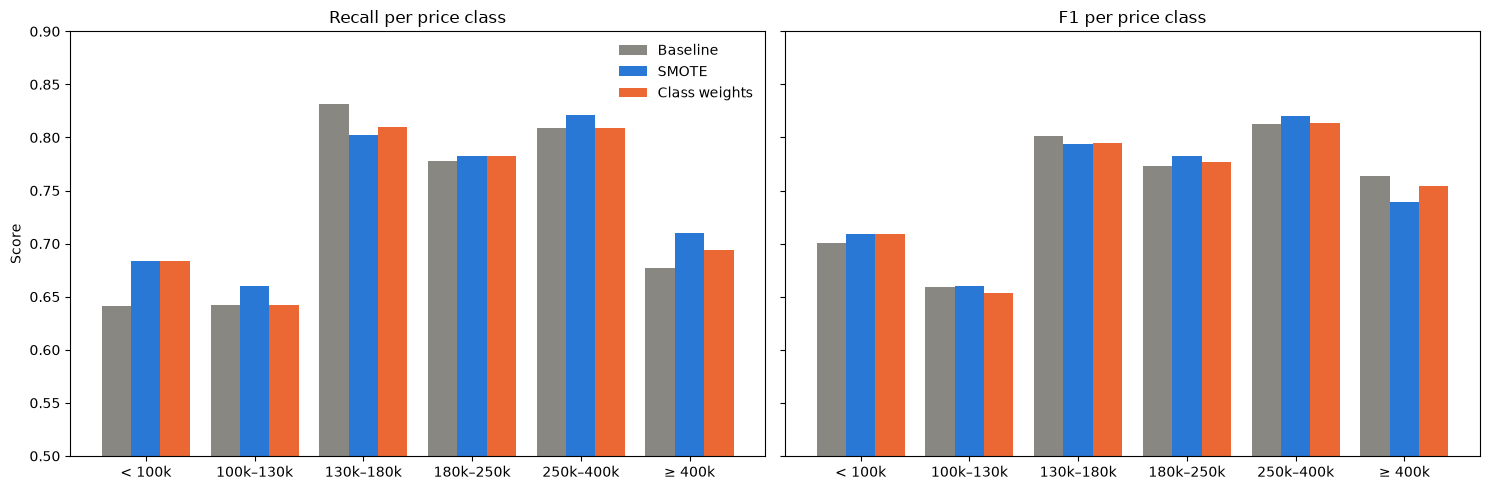

In [9]:
cv5 = [split for split in splits if split["Setup"] == "CV k=5, stratified"]
X_base, y_base = data[BASELINE]

# What SMOTE and the class weights do to one training part (first fold of the 5-fold CV)
y_train = y_base.loc[cv5[0]["train"]]
encoded = make_preprocessor("onehot").fit_transform(X_base.loc[y_train.index], y_train)
_, y_smote = smote_keep_missing(encoded, y_train)
print(f"Training houses in the first fold: {len(y_train):,} real, {len(y_smote):,} after SMOTE")
display(pd.DataFrame({
    "Real houses": y_train.value_counts().sort_index().to_numpy(),
    "After SMOTE": y_smote.value_counts().sort_index().to_numpy(),
    "Class weight": pd.Series(balanced_weights(y_train)).groupby(y_train.to_numpy()).first().to_numpy(),
}, index=CLASS_NAMES).round(3))

# Out-of-fold predictions of the three variants on the same 5 folds
IMBALANCE = ["Baseline", "SMOTE", "Class weights"]
y_true = y_base.loc[normal_houses]
oof = {}
for name in IMBALANCE:
    v = next(v for v in VARIANTS if v["Variant"] == name)
    pipeline = build_pipeline(v["strategy"], smote=v["smote"])
    pred = pd.Series(0, index=normal_houses)
    for split in cv5:
        train = split["train"]
        fit_params = {} if v["weight_fn"] is None else {"model__sample_weight": v["weight_fn"](y_base.loc[train])}
        model = clone(pipeline).fit(X_base.loc[train], y_base.loc[train], **fit_params)
        pred.loc[split["test"]] = model.predict(X_base.loc[split["test"]])
    oof[name] = pred

print("Pooled out-of-fold metrics")
display(pd.DataFrame([
    {
        "Variant": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Macro Precision": precision_score(y_true, pred, average="macro"),
        "Macro Recall": recall_score(y_true, pred, average="macro"),
        "Macro F1": f1_score(y_true, pred, average="macro"),
    }
    for name, pred in oof.items()
]).set_index("Variant").round(4))

per_class = pd.concat({
    name: pd.DataFrame({
        "Precision": precision_score(y_true, pred, average=None),
        "Recall": recall_score(y_true, pred, average=None),
        "F1": f1_score(y_true, pred, average=None),
    }, index=CLASS_NAMES)
    for name, pred in oof.items()
}, axis=1)
print("Precision, recall and F1 per class")
display(per_class.round(4))

# Recall and F1 per class side by side
COLORS_IMB = {"Baseline": "#898781", "SMOTE": "#2a78d6", "Class weights": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
width = 0.27
for ax, metric in zip(axes, ["Recall", "F1"]):
    for offset, name in zip((-width, 0, width), IMBALANCE):
        ax.bar(np.arange(len(CLASS_NAMES)) + offset, per_class[(name, metric)], width, label=name, color=COLORS_IMB[name])
    ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES)
    ax.set_title(f"{metric} per price class", fontsize=12)
    ax.set_ylim(0.5, 0.9)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Score")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

#### Interpretation of the methods for imbalanced classes
* **What the methods do to the training data:** in the first fold, SMOTE grows the training part from 2,340 to 4,974 houses. Every class is filled up to the 829 houses of `130k–180k`, so `≥ 400k` gets 780 synthetic houses for its 49 real ones (about 16 per real house), and `< 100k` gets 639 for its 190. Class weights keep the 2,340 houses but weight a house ≥ \$400k with 7.959 and a house of \$130k–\$180k with 0.470.
* **Both methods shift predictions from the largest class towards the smaller ones:**
  * Recall rises for `< 100k` (0.641 → 0.684 with both methods) and for `≥ 400k` (0.677 → 0.710 with SMOTE, 0.694 with class weights).
  * Recall falls for `130k–180k`, the largest class (0.831 → 0.802 with SMOTE, 0.810 with class weights).
  * The precision of the small classes falls: `≥ 400k` from 0.875 to 0.772 (SMOTE) and 0.827 (class weights), `< 100k` from 0.772 to 0.736 (both).
* **Gains and losses per class roughly cancel.** With SMOTE, the F1 rises for `< 100k` (+0.0085), `180k–250k` (+0.0094) and `250k–400k` (+0.0074), but falls for `130k–180k` (−0.0080) and `≥ 400k` (−0.0241). The pooled macro-F1 on these 5 folds is almost unchanged: 0.7509 with SMOTE and 0.7503 with class weights, vs. 0.7518 for the baseline. The accuracy hardly moves either (0.7638 and 0.7614 vs. 0.7641), while the macro recall rises (0.7431 and 0.7367 vs. 0.7298) and the macro precision falls (0.7594 and 0.7664 vs. 0.7806).
* **The rarest class loses F1 with both methods:** more houses ≥ \$400k are found (44 of 62 with SMOTE, 43 with class weights, instead of 42), but there are more false alarms, so the precision drops more than the recall rises. With only about 50 real luxury houses per training part, SMOTE's synthetic houses are all interpolations between the same few houses. This enlarges the region the model assigns to the class without defining its border better.
* **The same trade-off as threshold moving:** notebook 03 (Section 5) found the same pattern for per-class thresholds: higher recall and lower precision for the rare classes, and no macro-F1 gain on these folds. All three methods move the decision boundary towards the large classes. None of them adds information that would separate the borderline houses next to a class boundary better.

### 6. Conclusion
* **Data preparation:** with the default model, none of the eight data preparation changes improves on the baseline of notebook 02. All their differences are below 0.01 macro-F1, small compared with the spread over the splits, and the encodings other than one-hot are probably slightly worse.
* **Imbalanced classes:**
  * SMOTE is the only change with a clearly positive average: +0.0115 macro-F1 over all 70 splits (better on 44), with a lower gap (0.238 vs. 0.249). The gain comes from the holdout splits; on the cross-validation folds it is close to 0 (+0.0018).
  * Class weights gain less (+0.0036).
  * Per class, both methods trade precision of the small classes for recall, like the thresholds in notebook 03, and the rarest class `≥ 400k` loses F1 with both.
* **Overfitting:** the training macro-F1 stays 1.0 for every variant, including SMOTE and class weights, and the gap stays between 0.24 and 0.26. The main problem is the overfitting of the model, so regularizing it through its hyperparameters promises more than further data preparation.
* **Setup for notebook 05:** the hyperparameter tuning keeps the baseline: one-hot encoding, without the nearly constant features and the 5 extreme houses, and without SMOTE. On the stratified 5-fold cross-validation that notebook 05 uses for tuning, SMOTE brings no gain (0.7479 vs. 0.7494).
* **Worth checking again with the tuned model:**
  * SMOTE, for its gain on the holdout splits.
  * Size totals, the only data preparation variant that beats the baseline on the holdout splits on average (+0.0047).
  * Without redundant, which costs only 0.004 macro-F1 but has 5 fewer features, so the feature importance is not split between near-duplicates.